# Plant Disease Classification
Classifying tomato, potato and pepper leaf diseases from the PlantVillage dataset with a frozen MobileNetV3Large base.

In [1]:
import os
import random
import shutil
import time
import numpy as np
import tensorflow as tf
from keras import layers, models
from keras.applications import MobileNetV3Large
from keras.optimizers import Adam
from keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("emmarex/plantdisease")
directory = os.path.join(path, "PlantVillage")

## Looking at the data

In [3]:
# the download has a duplicate PlantVillage folder inside it, so skip that
class_names = sorted([d for d in os.listdir(directory)
                      if os.path.isdir(os.path.join(directory, d)) and d != "PlantVillage"])

counts = {}
for c in class_names:
    files = [f for f in os.listdir(os.path.join(directory, c)) if f.lower().endswith((".jpg", ".jpeg"))]
    counts[c] = len(files)
    print(f"{c}: {len(files)}")
print("Total:", sum(counts.values()))

Pepper__bell___Bacterial_spot: 997
Pepper__bell___healthy: 1477
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Tomato_Bacterial_spot: 2127
Tomato_Early_blight: 1000
Tomato_Late_blight: 1909
Tomato_Leaf_Mold: 952
Tomato_Septoria_leaf_spot: 1771
Tomato_Spider_mites_Two_spotted_spider_mite: 1676
Tomato__Target_Spot: 1404
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208
Tomato__Tomato_mosaic_virus: 373
Tomato_healthy: 1591
Total: 20637


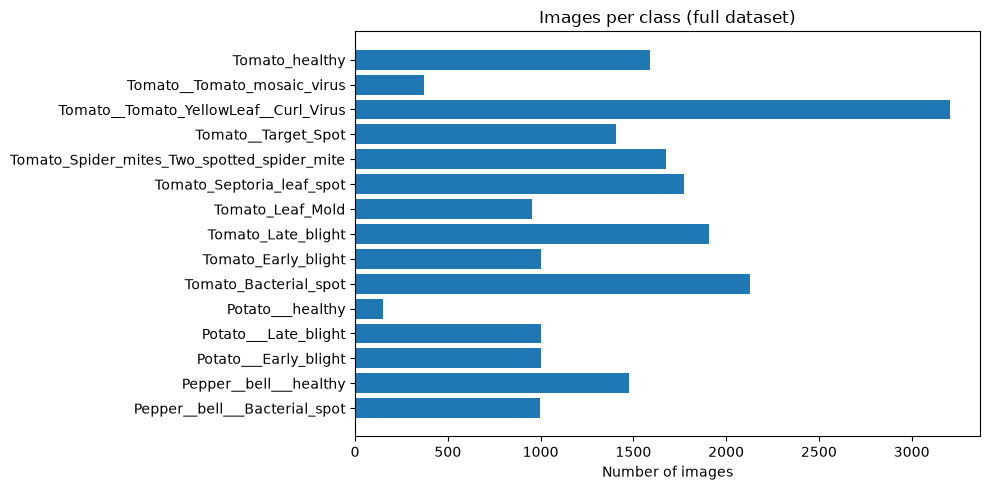

In [4]:
plt.figure(figsize=(10, 5))
plt.barh(list(counts.keys()), list(counts.values()))
plt.title("Images per class (full dataset)")
plt.xlabel("Number of images")
plt.tight_layout()
plt.show()

## Subsample and split
Training on all 20,000 images is too slow on my laptop's CPU, so I take up to 400 images per class. 15% of each class goes into a test folder that the model never sees during training, and the rest is split 82/18 into train and validation (roughly 70/15/15 overall).

In [5]:
PER_CLASS = 400
TEST_FRAC = 0.15
random.seed(42)

if os.path.exists("data"):
    shutil.rmtree("data")

for c in class_names:
    files = sorted([f for f in os.listdir(os.path.join(directory, c)) if f.lower().endswith((".jpg", ".jpeg"))])
    random.shuffle(files)
    files = files[:PER_CLASS]
    n_test = int(len(files) * TEST_FRAC)
    for i, f in enumerate(files):
        split = "test" if i < n_test else "train_val"
        os.makedirs(os.path.join("data", split, c), exist_ok=True)
        shutil.copy(os.path.join(directory, c, f), os.path.join("data", split, c, f))

for split in ["train_val", "test"]:
    total = sum(len(os.listdir(os.path.join("data", split, c))) for c in class_names)
    print(split, total)

train_val 4868
test 857


In [6]:
BATCH = 16
SIZE = (224, 224)

def data_loading(subset):
    dataset = image_dataset_from_directory(
        "data/train_val",
        labels = "inferred",
        label_mode = "categorical",
        validation_split = 0.18,
        subset = subset,
        shuffle = True,
        seed = 123,
        batch_size = BATCH,
        image_size = SIZE,
    )
    return dataset

train_ds = data_loading("training")
val_ds = data_loading("validation")

# test set is not shuffled so predictions line up with the labels
test_ds = image_dataset_from_directory(
    "data/test",
    labels = "inferred",
    label_mode = "categorical",
    shuffle = False,
    batch_size = BATCH,
    image_size = SIZE,
)
class_names = train_ds.class_names
num_classes = len(class_names)

Found 4868 files belonging to 15 classes.


Using 3992 files for training.


Found 4868 files belonging to 15 classes.


Using 876 files for validation.


Found 857 files belonging to 15 classes.


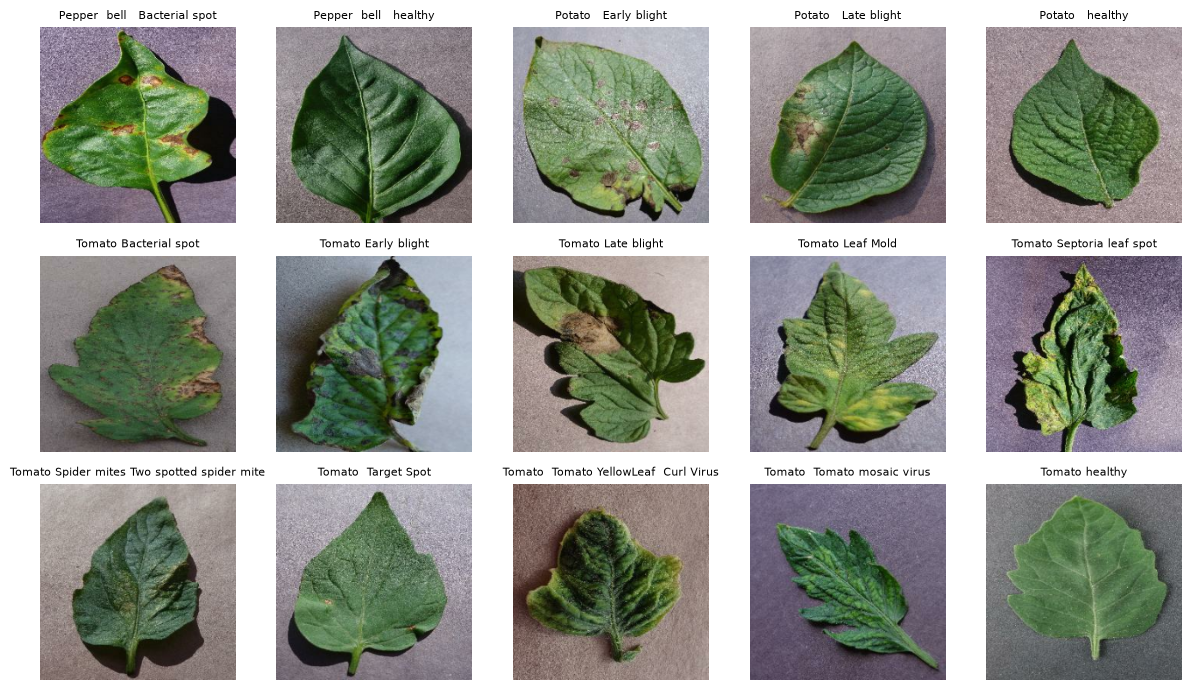

In [7]:
# one example of each class
rep_images = {c: None for c in class_names}
for img, label in train_ds.unbatch():
    c = class_names[np.argmax(label.numpy())]
    if rep_images[c] is None:
        rep_images[c] = img.numpy().astype("uint8")
    if all(v is not None for v in rep_images.values()):
        break

plt.figure(figsize=(12, 7))
for i, c in enumerate(class_names):
    plt.subplot(3, 5, i + 1)
    plt.imshow(rep_images[c])
    plt.title(c.replace("_", " "), fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Model
Same setup as my cancer detection models: frozen MobileNetV3Large with ImageNet weights, then three dense layers and a softmax. MobileNetV3 in Keras rescales the pixels itself so the images go in as 0-255.

In [8]:
def create_model(num_classes):
    pre_model = MobileNetV3Large(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    # freeze the base so only the new layers train
    pre_model.trainable = False

    x = pre_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dense(128, activation='relu')(x)
    output_layer = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs=pre_model.input, outputs=output_layer)
    model.compile(
        loss='categorical_crossentropy',
        optimizer=Adam(learning_rate=0.0001),
        metrics=['accuracy']
    )
    return model

tf.random.set_seed(42)
model = create_model(num_classes)
print("Trainable params:", sum(np.prod(w.shape) for w in model.trainable_weights))

Trainable params: 1576463


In [9]:
start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=8, verbose=2)
print(f"Training took {(time.time() - start) / 60:.1f} minutes")

Epoch 1/8


250/250 - 64s - 257ms/step - accuracy: 0.7277 - loss: 1.0189 - val_accuracy: 0.8904 - val_loss: 0.4054


Epoch 2/8


250/250 - 53s - 210ms/step - accuracy: 0.9153 - loss: 0.3142 - val_accuracy: 0.9224 - val_loss: 0.2816


Epoch 3/8


...

Epoch 7/8


250/250 - 74s - 297ms/step - accuracy: 0.9952 - loss: 0.0383 - val_accuracy: 0.9429 - val_loss: 0.1551


Epoch 8/8


250/250 - 70s - 281ms/step - accuracy: 0.9970 - loss: 0.0260 - val_accuracy: 0.9498 - val_loss: 0.1338


Training took 8.3 minutes


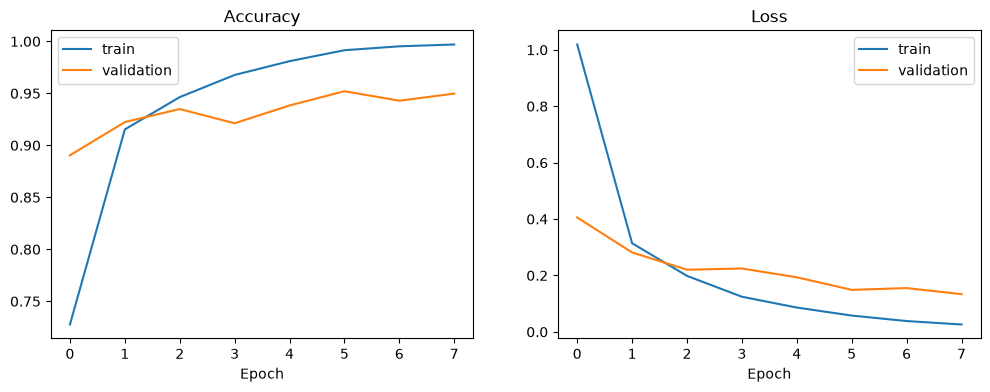

In [10]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.show()

## Test set results

In [11]:
loss, accuracy = model.evaluate(test_ds)
print(f"Test loss: {loss:.4f}, Test accuracy: {accuracy:.4f}")

 1/54 ━━━━━━━━━━━━━━━━━━━━ 41s 779ms/step - accuracy: 1.0000 - loss: 0.0233

 2/54 ━━━━━━━━━━━━━━━━━━━━ 22s 430ms/step - accuracy: 0.9844 - loss: 0.0636

 3/54 ━━━━━━━━━━━━━━━━━━━━ 20s 408ms/step - accuracy: 0.9826 - loss: 0.0656

 4/54 ━━━━━━━━━━━━━━━━━━━━ 20s 404ms/step - accuracy: 0.9831 - loss: 0.0624

 5/54 ━━━━━━━━━━━━━━━━━━━━ 23s 483ms/step - accuracy: 0.9815 - loss: 0.0604

...

52/54 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9542 - loss: 0.1425

53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.9539 - loss: 0.1435

54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.9536 - loss: 0.1443

54/54 ━━━━━━━━━━━━━━━━━━━━ 12s 221ms/step - accuracy: 0.9382 - loss: 0.1895


Test loss: 0.1895, Test accuracy: 0.9382


In [12]:
y_true = np.concatenate([np.argmax(y, axis=1) for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

 1/54 ━━━━━━━━━━━━━━━━━━━━ 45s 867ms/step

 2/54 ━━━━━━━━━━━━━━━━━━━━ 8s 172ms/step 

 3/54 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step

 4/54 ━━━━━━━━━━━━━━━━━━━━ 8s 175ms/step

 5/54 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step

...

52/54 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step

53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step

54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step

54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 448ms/step


                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot      0.967     0.983     0.975        60
                     Pepper__bell___healthy      0.983     0.983     0.983        60
                      Potato___Early_blight      1.000     0.983     0.992        60
                       Potato___Late_blight      0.937     0.983     0.959        60
                           Potato___healthy      1.000     0.909     0.952        22
                      Tomato_Bacterial_spot      0.964     0.883     0.922        60
                        Tomato_Early_blight      0.825     0.867     0.846        60
                         Tomato_Late_blight      0.964     0.900     0.931        60
                           Tomato_Leaf_Mold      1.000     0.950     0.974        60
                  Tomato_Septoria_leaf_spot      0.844     0.900     0.871        60
Tomato_Spider_mites_Two_spotted_spider_mite      0.891     0.950

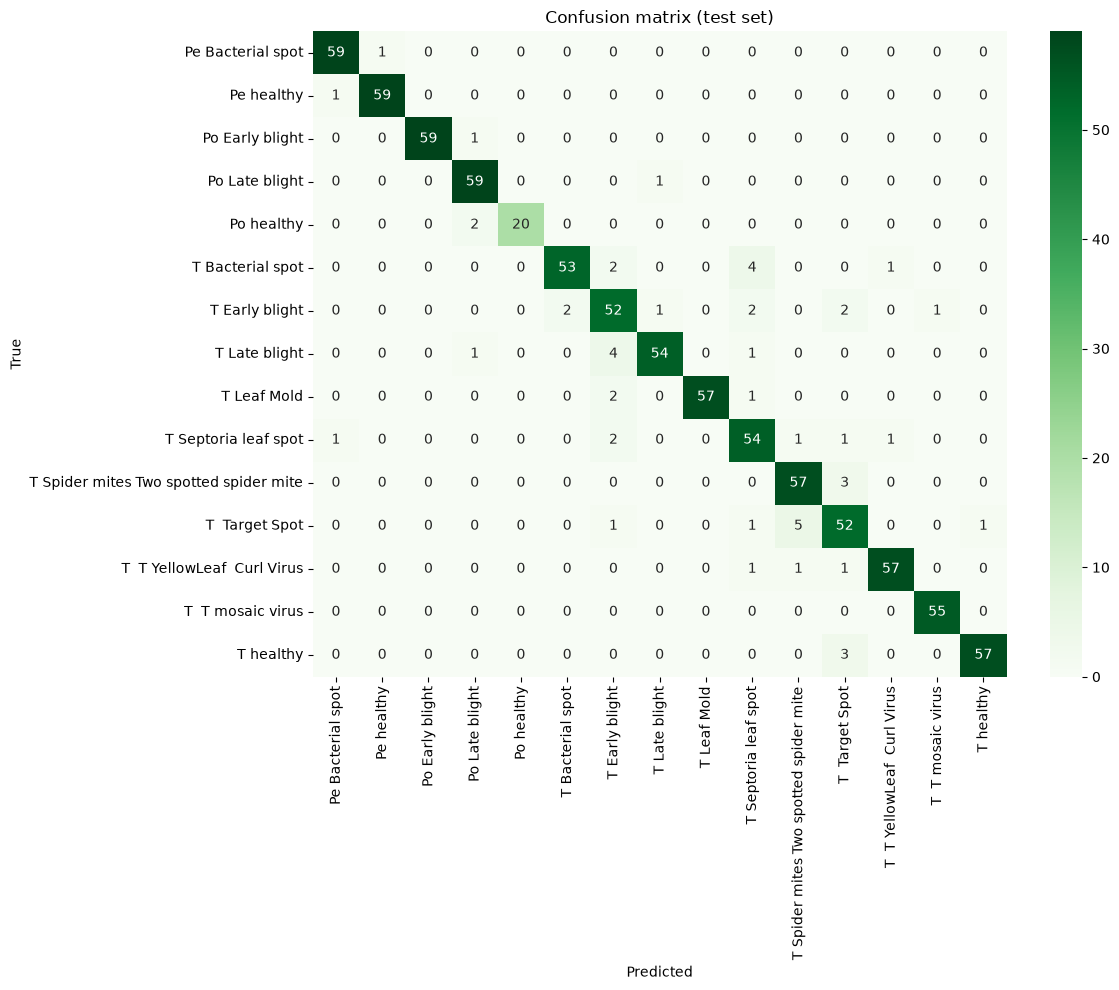

In [13]:
cm = confusion_matrix(y_true, y_pred)
short = [c.replace("Tomato_", "T ").replace("Potato___", "Po ").replace("Pepper__bell___", "Pe ").replace("_", " ") for c in class_names]
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=short, yticklabels=short)
plt.title("Confusion matrix (test set)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [14]:
os.makedirs("models", exist_ok=True)
model.save("models/plant_disease_model.keras")
print(f"Model size: {os.path.getsize('models/plant_disease_model.keras') / 1e6:.1f} MB")

Model size: 31.6 MB


## Grad-CAM
The same Grad-CAM code I used for the cancer models, using the `conv_1_bn` layer (the last conv block of MobileNetV3Large). This shows which parts of the leaf the model is looking at.

In [15]:
def generate_gradcam_heatmap(model, image_array, last_conv_layer_name, pred_index=None):
    # model that outputs the last conv layer activations and the predictions
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(image_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # gradient of the predicted class with respect to the conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # weight each channel by how important it is, then sum
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # normalise between 0 and 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def overlay_gradcam(img, heatmap, alpha=0.4):
    # resize heatmap to the image and colour it with jet
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (img.shape[0], img.shape[1])).numpy()[:, :, 0]
    heatmap = np.uint8(255 * heatmap)
    jet = plt.colormaps.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap] * 255

    superimposed_img = jet_heatmap * alpha + img
    return tf.keras.utils.array_to_img(superimposed_img)

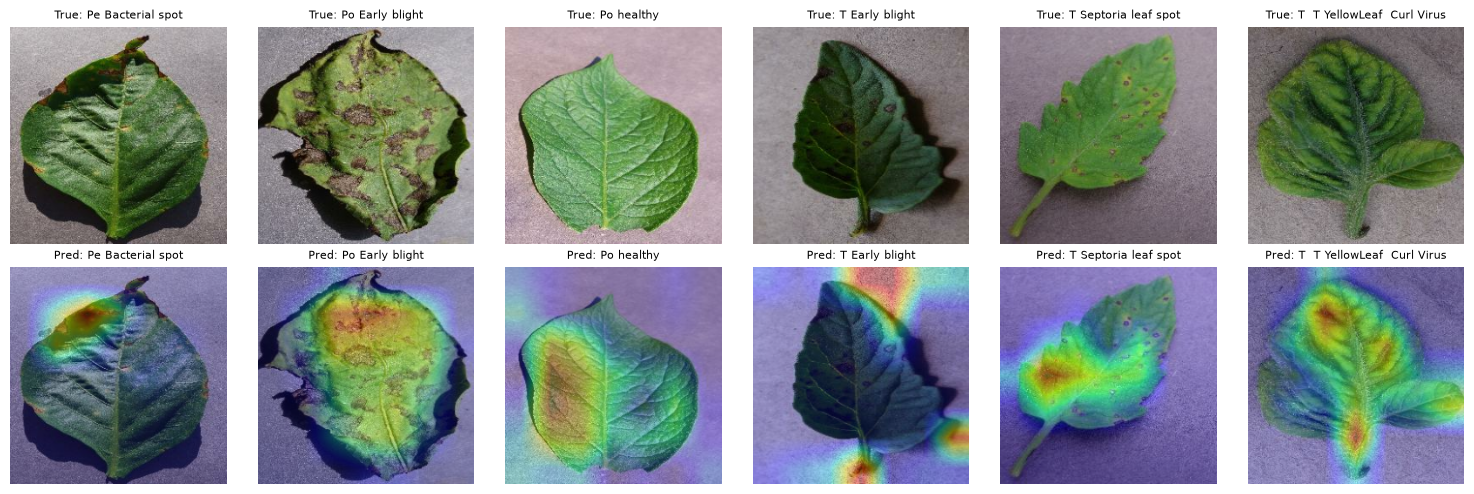

In [16]:
# Grad-CAM on a few test images from different classes
test_images = np.concatenate([x.numpy() for x, y in test_ds])
picks = [list(y_true).index(k) for k in [0, 2, 4, 6, 9, 12]]  # first test image of six classes

plt.figure(figsize=(15, 5))
for i, idx in enumerate(picks):
    img = test_images[idx]
    heatmap = generate_gradcam_heatmap(model, img[np.newaxis, ...], "conv_1_bn")

    plt.subplot(2, 6, i + 1)
    plt.imshow(img.astype("uint8"))
    plt.title(f"True: {short[y_true[idx]]}", fontsize=8)
    plt.axis("off")

    plt.subplot(2, 6, i + 7)
    plt.imshow(overlay_gradcam(img, heatmap))
    plt.title(f"Pred: {short[y_pred[idx]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.savefig("grad_cam_examples.png")
plt.show()